<a href="https://colab.research.google.com/github/Shukti-cyber/ML/blob/main/TmieSeries_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv('AirPassengers.csv')
df

,Month,Passengers
0,15-01-1949,112
1,15-02-1949,118
2,15-03-1949,132
3,15-04-1949,129
4,15-05-1949,121
...,...,...
139,15-08-1960,606
140,15-09-1960,508
141,15-10-1960,461
142,15-11-1960,390


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Month       144 non-null    object
 1   Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [6]:
df=df.set_index('Month')

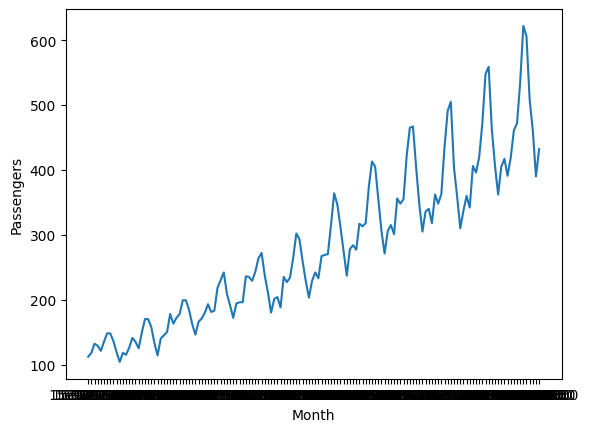

In [9]:
sns.lineplot(x=df.index, y=df['Passengers'])
plt.show()

([<matplotlib.axis.XTick at 0x7aa4fa638a50>,
 [Text(0.0, 0, '15-01-1949'),
  Text(1.0, 0, '15-02-1949'),
  Text(2.0, 0, '15-03-1949'),
  Text(3.0, 0, '15-04-1949'),
  Text(4.0, 0, '15-05-1949'),
  Text(5.0, 0, '15-06-1949'),
  Text(6.0, 0, '15-07-1949'),
  Text(7.0, 0, '15-08-1949'),
  Text(8.0, 0, '15-09-1949'),
  Text(9.0, 0, '15-10-1949'),
  Text(10.0, 0, '15-11-1949'),
  Text(11.0, 0, '15-12-1949'),
  Text(12.0, 0, '15-01-1950'),
  Text(13.0, 0, '15-02-1950'),
  Text(14.0, 0, '15-03-1950'),
  Text(15.0, 0, '15-04-1950'),
  Text(16.0, 0, '15-05-1950'),
  Text(17.0, 0, '15-06-1950'),
  Text(18.0, 0, '15-07-1950'),
  Text(19.0, 0, '15-08-1950'),
  Text(20.0, 0, '15-09-1950'),
  Text(21.0, 0, '15-10-1950'),
  Text(22.0, 0, '15-11-1950'),
  Text(23.0, 0, '15-12-1950'),
  Text(24.0, 0, '15-01-1951'),
  Text(25.0, 0, '15-02-1951'),
  Text(26.0, 0, '15-03-1951'),
  Text(27.0, 0, '15-04-1951'),
  Text(28.0, 0, '15-05-1951'),
  Text(29.0, 0, '15-06-1951'),
  Text(30.0, 0, '15-07-1951'),
  Te

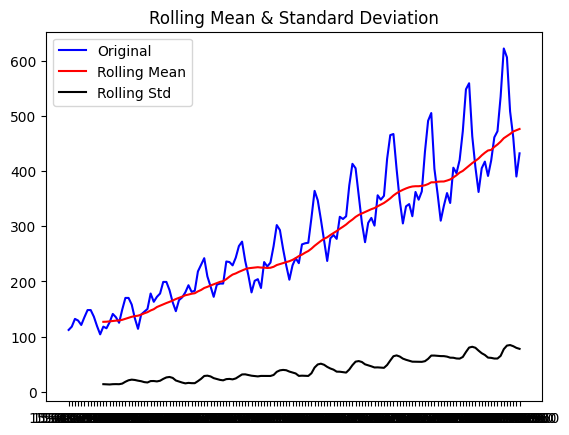

In [10]:
rolmean=df['Passengers'].rolling(window=12).mean()
rolstd=df['Passengers'].rolling(window=12).std()

#Plot rolling statics
orig = plt.plot(df['Passengers'], color='blue',label='Original')
mean = plt.plot(rolmean, color='red', label='Rolling Mean')
std = plt.plot(rolstd, color='black', label = 'Rolling Std')
plt.legend(loc='best')
plt.title('Rolling Mean & Standard Deviation')
plt.show
plt.xticks(ticks=df.index)

In [11]:
from statsmodels.tsa.stattools import adfuller
adfuller_result=adfuller(df['Passengers'])
print(f'ADF Statistic: {adfuller_result[0]}')
print(f'p-value: {adfuller_result[1]}')

ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641


/tmp/ipykernel_463/3436044516.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller_result=adfuller(df['Passengers'])


In [13]:
diff = df['Passengers']-df['Passengers'].shift(2)
diff.dropna(inplace=True)
adfuller_result=adfuller(diff)
print(f'ADF Statistic: {adfuller_result[0]}')
print(f'p-value: {adfuller_result[1]}')

ADF Statistic: -2.961695135555418
p-value: 0.03862975767698902


/tmp/ipykernel_463/1519871684.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller_result=adfuller(diff)


In [ ]:
y_train = diff[:114]
y_test = diff[114:]

Build Arima model

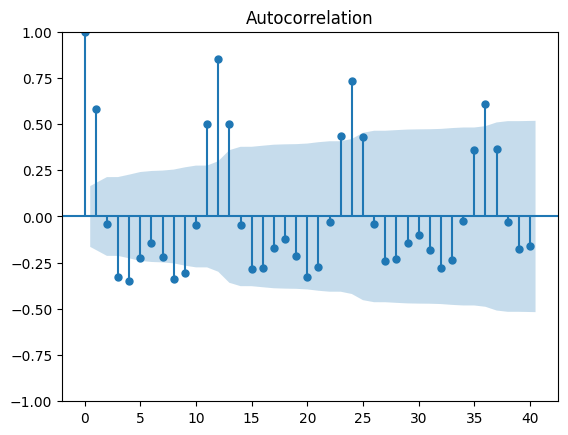

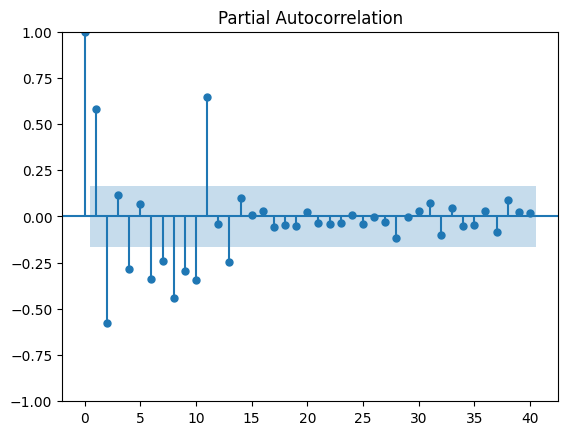

In [14]:
from statsmodels.tsa.stattools import acf,pacf
import statsmodels.api as sm
fig=sm.graphics.tsa.plot_acf(diff,lags=40)
fig=sm.graphics.tsa.plot_pacf(diff,lags=40)

In [15]:
import warnings

In [20]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 1. Reload the dataframe fresh to avoid carry-over modifications
df_clean = pd.read_csv('AirPassengers.csv')

# 2. Convert to datetime and force dates to the 1st of each month (Month Start)
df_clean['Month'] = pd.to_datetime(df_clean['Month'], format='%d-%m-%Y')
df_clean['Month'] = df_clean['Month'].map(lambda dt: dt.replace(day=1))
df_clean.set_index('Month', inplace=True)
df_clean = df_clean.asfreq('MS')

# 3. Create differenced series and drop NaNs
diff = df_clean['Passengers'] - df_clean['Passengers'].shift(2)
diff = diff.dropna()

# 4. Split train and test data
y_train = diff[:114]
y_test = diff[114:]

# 5. Fit the ARIMA model on train data
model = ARIMA(y_train, order=(11, 0, 12))
model_fit = model.fit()

# 6. Prediction
ypred_train = model_fit.predict(start=y_train.index[0], end=y_train.index[-1])
ypred_test = model_fit.predict(start=y_test.index[0], end=y_test.index[-1])

# 7. Evaluation
mse_train = mean_squared_error(y_train, ypred_train)
mse_test = mean_squared_error(y_test, ypred_test)

print(f"Train MSE: {mse_train}")
print(f"Test MSE: {mse_test}")

Train MSE: 87.02466903056184
Test MSE: 1042.693420917965


In [22]:
#Modelling

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Instantiate and fit the SARIMAX model on training data
# Note: using the same order (11,0,12) with seasonal period 12
model = SARIMAX(y_train, order=(11, 0, 12))
sarimax_fit = model.fit(disp=False)

# Predict
ypred_train = sarimax_fit.predict(start=y_train.index[0], end=y_train.index[-1])
ypred_test = sarimax_fit.predict(start=y_test.index[0], end=y_test.index[-1])

#Evaluation
print("Train R2 of SARIMAX model:", r2_score(y_train, ypred_train))
print("Test R2 of SARIMAX model:", r2_score(y_test, ypred_test))

Train R2 of SARIMAX model: 0.9521466097502564
Test R2 of SARIMAX model: 0.852628479127938
